In [1]:
import joblib
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
#Cargar el modelo multiple_regression
artifacts = joblib.load("../../../models/exp01_ols_with_imc/multiple_regression.joblib")
type(artifacts)

dict

In [4]:
#Explorando las claves del diccionario 
artifacts.keys()

dict_keys(['model', 'features', 'X_train', 'y_train', 'y_test', 'X_test', 'metrics'])

In [5]:
#Alamacenar los valores de las claves en nuestras propias variables
model = artifacts["model"]
X_train = artifacts["X_train"]
y_train = artifacts["y_train"]
y_test = artifacts["y_test"]
X_test = artifacts["X_test"]
metrics = artifacts["metrics"]

In [6]:
#Explorar el modelo (Opcional)
type(model)

sklearn.linear_model._base.LinearRegression

In [7]:
y_pred = model.predict(X_test)

In [8]:
residuos = y_test - y_pred
residuos.head(10)

46     0.088715
9      1.585771
206   -1.141044
139   -0.772730
60     0.825793
33     0.673508
297   -0.164067
186   -0.333458
296    1.269533
277    2.922190
Name: PESO (KG), dtype: float64

**ANALISIS DE RESIDUOS**

**1.- Distribución de los residuos**

In [9]:
#Verificar numero de clases
len(residuos.unique())

63

<function matplotlib.pyplot.show(close=None, block=None)>

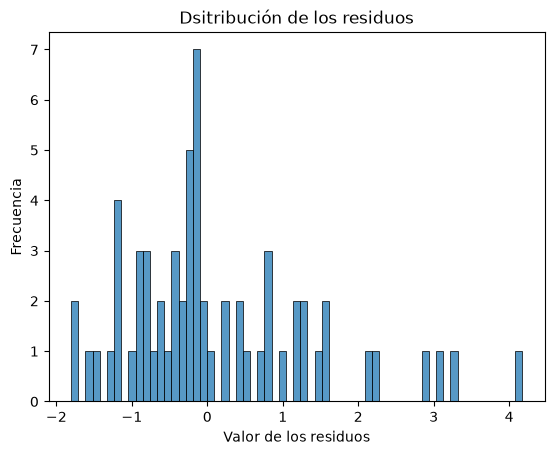

In [10]:
#Graficar histograma de residuos 
sns.histplot(residuos, bins=63)
plt.title("Dsitribución de los residuos")
plt.xlabel("Valor de los residuos")
plt.ylabel("Frecuencia")
plt.savefig("../../../graphics/exp01_ols_with_imc/histograma_residuos.png")
plt.show

**Valor Residual**

Se observa en el Histograma que los valores de los residuos no se distribuyen de forma uniforme alreddor del valor 0, también presenta una cola de residuos muy alargada (a la derecha), es decir, en algunos casos el modelo subestimo con fuerza y la media sigue este alargamiento de los errores.

En este punto de analisis de la distribución nos interesa encontrar que la media de los valores residuales tenga un valor cercano a CERO.

**2.- Residuos contra Valores predichos**

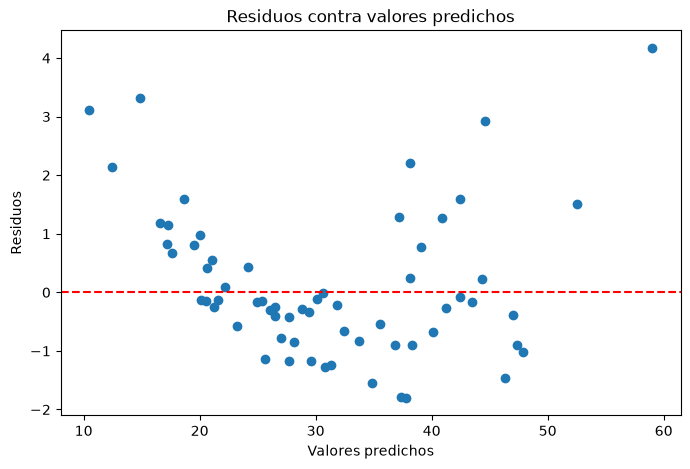

In [11]:
#El peso predicho contra el error

plt.figure(figsize=(8,5))
plt.scatter(y_pred, residuos)
plt.axhline(0, linestyle="--", color="red")

plt.xlabel("Valores predichos")
plt.ylabel("Residuos")
plt.title("Residuos contra valores predichos")

plt.show()

**Valores Predichos**

Desde el Histograma de los residuos se observa que existen residuos positivos muy alejados de la media, sin embargo no es, sino hasta visualizar el scatterplot de los valores predichos contra los residuos que observamos la "forma" o "tendencia" que siguen. Consinderando que 4/6 de los errores se ubican en los extremos de las predicciones del modelo.

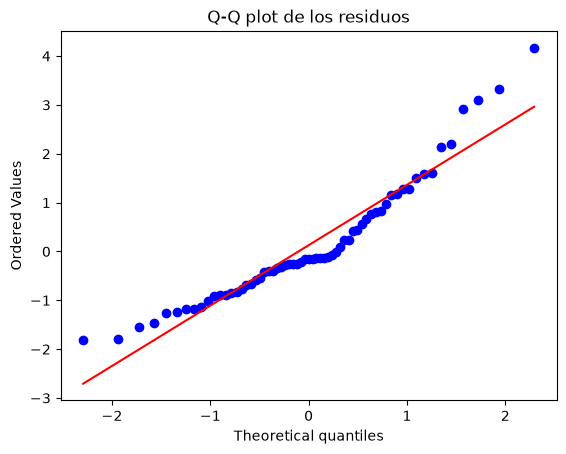

In [14]:
import scipy.stats as stats

stats.probplot(residuos, dist="norm", plot=plt)

plt.title("Q-Q plot de los residuos")
plt.show()

In [13]:
!pip install scipy

^C


**Diagnóstico**
De acuerdo a la información de los graficos:
1.- Histograma de la distribución de los residuos
2.- Scatterplot de los valores predichos vs los reeales
3.- Q-Q plot

Determinamos que los residuos no siguen una distribución normal, el modelo subestima de forma descontrolada, y se presume una relación no lineal entre X y y.

Sugerencias:
-Probar un modelo no lineal 